# Icelines

Comparison of `DustPy` (full coagulation) and `TriPoDPy` for a disk in which the fragmentation velocity
changes at the temperatures 150 K, 80 K and 44 K, mimicking ice lines. 

The same setup as shown in [Pfeil et al. 2024](https://scixplorer.org/abs/2024A&A...691A..45P/abstract?fromADS=true&ads_compat=1) Fig. 9

Before running this notebook, run both simulations:
* `python Icelines.py` in this folder (TriPoDPy, writes `data_ice/`)

For the `DustPy` simulation you can either:
* use the sample snapshots from the `DustPy` simulation saved in `/Dustpy_setups/sample_data_Iceline` at [10<sup>3</sup>, 10<sup>4</sup>, 10<sup>5</sup> or 3*10<sup>5</sup>] Years
* or run `python Dustpy_setups/Icelines.py` (DustPy, writes to `data_ice_DP/`) this might take a day or two

In [ ]:
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import dustpy as dp
from tripodpy.utils import get_q, get_size_distribution

au = dp.constants.au
yr = dp.constants.year

# figures are saved here
plot_dir = Path("plots/iceline")
plot_dir.mkdir(parents=True, exist_ok=True)

## Read data

In [ ]:
dp_path = Path("Dustpy_setups/sample_data_Iceline")  # DustPy output
tp_path = Path("data_ice")                # TriPoDPy output

In [3]:
def read_dustpy(path):
    """Read a DustPy run and compute the quantities compared below."""
    reader = dp.hdf5writer()
    reader.datadir = str(path)
    data = reader.read.all()

    a = data.dust.a[0, 0]
    Sigma_d = data.dust.Sigma

    # a_max: particle size below which 99% of the dust mass is contained
    cum_mass = np.cumsum(Sigma_d, axis=-1)
    a_max = a[np.argmax(cum_mass / cum_mass[..., -1:] >= 0.99, axis=-1)]

    return SimpleNamespace(
        t=np.ravel(data.t),
        r=data.grid.r[0],
        a=a,
        Sigma_g=data.gas.Sigma,
        Sigma_d=Sigma_d,
        eps=data.dust.eps,
        a_1=(Sigma_d * a).sum(-1) / Sigma_d.sum(-1),  # mass-averaged particle size
        a_max=a_max,
    )


def read_tripodpy(path, a):
    """Read a TriPoDPy run and reconstruct its power-law size distribution
    on the particle size grid `a` (the DustPy grid)."""
    reader = dp.hdf5writer()
    reader.datadir = str(path)
    data = reader.read.all()

    Sigma_d = data.dust.Sigma  # (n_t, n_r, 2): small and large population
    a_max = data.dust.a[..., 4]

    # interfaces chosen such that the bin centres coincide with `a`
    A = np.mean(a[1:] / a[:-1])
    with np.errstate(divide="ignore", invalid="ignore"):
        q = get_q(Sigma_d, data.dust.s.min, a_max)
        _, _, Sigma_d_rec = get_size_distribution(
            Sigma_d.sum(-1),
            a_max,
            q=q,
            na=len(a),
            agrid_min=2 / (A + 1) * a[0],
            agrid_max=2 * A / (A + 1) * a[-1],
        )

    return SimpleNamespace(
        t=np.ravel(data.t),
        r=data.grid.r[0],
        a=a,
        Sigma_g=data.gas.Sigma,
        Sigma_d=Sigma_d_rec,
        eps=data.dust.eps,
        a_1=data.dust.a[..., 2],
        a_max=a_max,
    )

In [4]:
d_d = read_dustpy(dp_path)
d_t = read_tripodpy(tp_path, d_d.a)

for name, d in [("DustPy", d_d), ("TriPoDPy", d_t)]:
    print(f"{name:9s}: {len(d.t)} snapshots, t_end = {d.t[-1] / yr:.3g} yr")

# line styles for the comparison plots
styles = {"DustPy": dict(ls="-", c="k"), "TriPoDPy": dict(ls="--", c="C2")}

DustPy   : 5 snapshots, t_end = 3.02e+05 yr
TriPoDPy : 258 snapshots, t_end = 3.51e+05 yr


## Plots

### 2D distribution plot

/scratch-local/slurm-job-tmp-18182891/ipykernel_2452315/1472512156.py:15: UserWarning: Log scale: values of z <= 0 have been masked
  con = ax.contour(d.r / au, d.a, d.Sigma_d[it, ...].T, np.geomspace(vmin, vmax, int(np.log10(vmax/vmin))+1), norm=LogNorm())


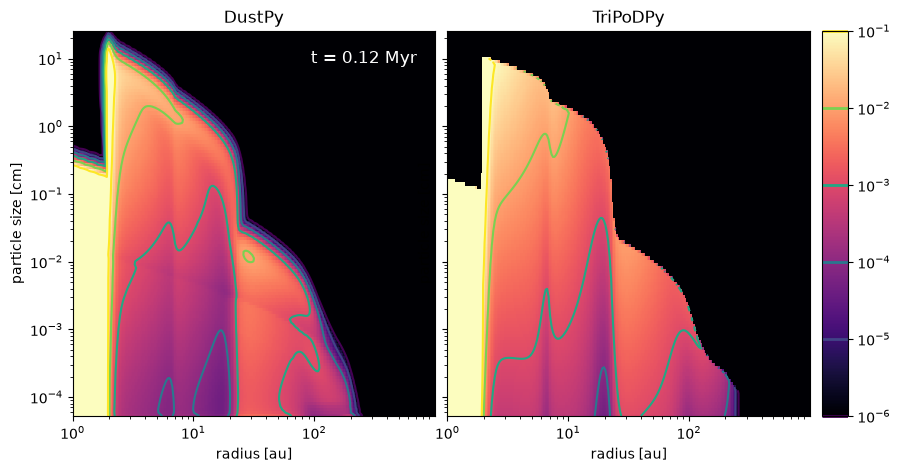

In [ ]:
f, axs = plt.subplots(1, 3, figsize=(10, 5), gridspec_kw={'width_ratios': [1, 1, 0.07], 'wspace': 0.05})

vmin = 1e-6
vmax = 1e-1
time = 1.2e5*yr

for ax, d, name  in zip(axs, [d_d, d_t],["DustPy", "TriPoDPy"]):

    it = np.abs(d.t - time).argmin()

    pcm = ax.pcolormesh(d.r / au, d.a, d.Sigma_d[it, ...].T, norm=LogNorm(vmin, vmax), cmap='magma')
    con = ax.contour(d.r / au, d.a, d.Sigma_d[it, ...].T, np.geomspace(vmin, vmax, int(np.log10(vmax/vmin))+1), norm=LogNorm())
    ax.set_facecolor(plt.get_cmap('magma')(0.0))  # empty bins (masked by LogNorm) drawn like values below vmin
    ax.loglog()
    ax.set_xlabel('radius [au]')
    ax.set_title(name)
    ax.set_ylabel('particle size [cm]')
axs[0].text(0.95, 0.95, f't = {d.t[it] / yr/1e6:.2g} Myr', transform=axs[0].transAxes, fontsize=12,color='white', verticalalignment='top',horizontalalignment='right')

axs[0].set_ylabel('particle size [cm]')
for ax in axs[1:]:
    ax.set_yticklabels('')

cb1 = f.colorbar(pcm, cax=axs[-1])
cb2 = f.colorbar(con, cax=axs[-1])
cb2.lines[0].set_linewidth(2)
plt.savefig(plot_dir / f"size_dist_{it}")

### Surface densities and $a_1$

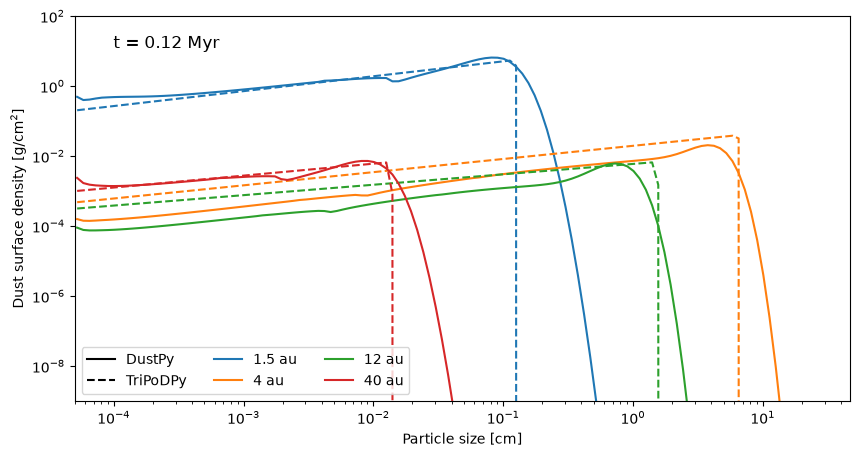

In [6]:
f, ax = plt.subplots(1, 1, figsize=(10, 5))

time = 1.2e5*yr
# one radius in each fragmentation-velocity zone: the ice lines lie at about
# 2 au (150 K), 7 au (80 K) and 23 au (44 K)
radii_au = [1.5, 4, 12, 40]

runs = [("DustPy", d_d, '-'), ("TriPoDPy", d_t, '--')]
for name, d, linestyle in runs:
    it = np.abs(d.t - time).argmin()  # show the snapshot time actually used by each run
    ax.plot([], [], color='k', linestyle=linestyle, label=f'{name}')

for r_ind, r_au in enumerate(radii_au):
    for name, d, linestyle in runs:
        it = np.abs(d.t - time).argmin()
        ir = np.abs(d.r/au - r_au).argmin()
        label = f'{r_au} au' if d is d_d else None
        ax.plot(d.a, d.Sigma_d[it, ir, :], label=label, linestyle=linestyle, color=f'C{r_ind % 10}')
ax.text(0.05, 0.95, f't = {time / yr/1e6:.2g} Myr', transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='left')

ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(loc='lower left',ncols=3)
ax.set_ylim(1e-9, 1e2)
ax.set_xlim(5e-5)
ax.set_ylabel('Dust surface density [g/cm$^2$]')
ax.set_xlabel('Particle size [cm]')
plt.savefig(plot_dir / "size_dist_radius_compare")